### Load all libraries

In [11]:
# * Means Import All ......
%load_ext autoreload
%autoreload 2
from src.config import *
from src.evaluate.arrange_bm import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Confusion Matrix & Classification Report for target type classification

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.87      0.83      1559
           1       0.74      0.66      0.70      1406
           2       0.79      0.89      0.84      1760
           3       0.98      0.98      0.98      2000
           4       0.87      0.88      0.87      1649
           5       0.96      0.90      0.93      2000
           6       0.93      0.77      0.84      2000
           7       0.87      0.97      0.91      2000
           8       0.82      0.86      0.84       591
           9       0.95      0.90      0.92      1035

    accuracy                           0.87     16000
   macro avg       0.87      0.87      0.87     16000
weighted avg       0.88      0.87      0.87     16000



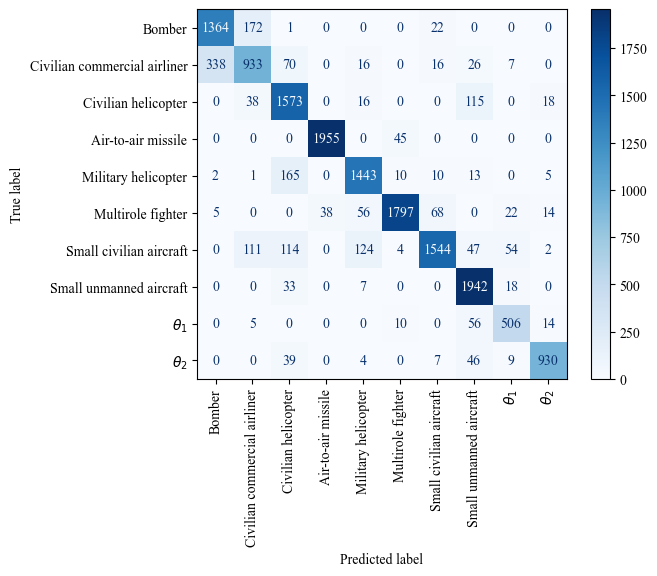

In [12]:
# ------------------- Rearranging probability distribution ---------------------  
data = pd.read_csv(os.path.join(os.getcwd() ,'output','target_type_belief_distribution', 'test_belief_distribution.csv'), header=None)

FD = pd.DataFrame(bm_arrange(data.iloc[:,:-1],data.iloc[:,-1]))

#  -------------------------------------- This Changes was made in suggestion of pilot -------------------------------- #
# Rename 'CruiseMissile' to 'Air-to-air Missile' before further processing
FD.iloc[:, -1] = FD.iloc[:, -1].replace('CruiseMissile', 'Air-to-air missile')
FD.iloc[:, -1] = FD.iloc[:, -1].replace('CivilianCommercialAirliner', 'Civilian commercial airliner')
FD.iloc[:, -1] = FD.iloc[:, -1].replace('CivilianHelicopter', 'Civilian helicopter')
FD.iloc[:, -1] = FD.iloc[:, -1].replace('SmallUnmanned', 'Small unmanned aircraft')
FD.iloc[:, -1] = FD.iloc[:, -1].replace('MultiroleFighter', 'Multirole fighter')
FD.iloc[:, -1] = FD.iloc[:, -1].replace('SmallCivilian', 'Small civilian aircraft')
FD.iloc[:, -1] = FD.iloc[:, -1].replace('MilitaryHelicopter', 'Military helicopter')

# Split into x and y
y = FD.iloc[:, -1].copy()  # True labels
x = FD.iloc[:, :-1]  # Prediction probabilities

ranges = [(0, 3999, '$\\theta_2$', [0, 1, 9]),
          (4000, 5999, '$\\theta_1$', [2, 4, 8]),
          (8000, 9999, '$\\theta_1$', [2, 4, 8])]

for start, end, label, cols in ranges:
    for i in range(start, end + 1): 
        if max(x.iloc[i, cols[0]], x.iloc[i, cols[1]], x.iloc[i, cols[2]]) == x.iloc[i, cols[2]]:
            y.iloc[i] = label

# Update the last column of the DataFrame
FD.iloc[:, -1] = y

# Define true labels and predicted labels
y_test = FD.iloc[:, -1]
x_test = FD.iloc[:, :-1]  # Use all but the last column
y_pred_labels = np.argmax(x_test.values, axis=1)

# Define the mapping from string labels to numbers
label_mapping = {
    "Bomber": 0,
    "Civilian commercial airliner": 1,
    "Civilian helicopter": 2,
    "Air-to-air missile": 3, 
    "Military helicopter": 4,
    "Multirole fighter": 5,
    "Small civilian aircraft": 6,
    "Small unmanned aircraft": 7,
    "$\\theta_1$": 8,
    "$\\theta_2$": 9,
}

# Convert y_test from strings to numbers
y_test_labels = y_test.replace(label_mapping)

# Generate confusion matrix and classification report
try:
    cm = confusion_matrix(y_test_labels, y_pred_labels)
except ValueError as e:
    print("Error:", e)

# Generate the classification report with string labels
report = classification_report(y_test_labels, y_pred_labels)

# Print the classification report
print("Classification Report:\n", report)

plt.rcParams.update({
    "font.family": "serif", 
    "font.serif": "Times New Roman"  
})

# Check if confusion matrix is generated
if 'cm' in locals():
    # Define confusion matrix labels
    cm_labels = list(label_mapping.keys())

    # Display the confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cm_labels)
    disp.plot(cmap=plt.cm.Blues)
    plt.xticks(rotation=90)

    # Save the figure
    output_path = os.path.join(os.getcwd(), 'output', 'target_type_confusion_matrix', 'Confusion_Matrix.png')
    plt.savefig(output_path, bbox_inches='tight', dpi=900)  

    plt.show()
else:
    print("Confusion matrix was not computed due to previous errors.")
